In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

(284807, 31)
Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173%


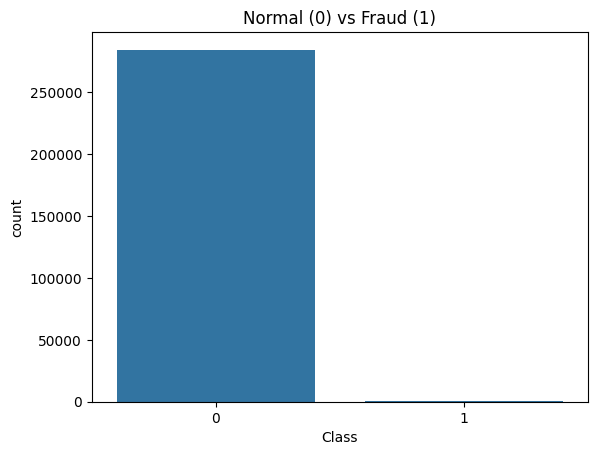

In [3]:
counts = df["Class"].value_counts()
print(counts)
print(f"Fraud percentage: {counts[1] / len(df) * 100:.3f}%")

sns.countplot(x="Class", data=df)
plt.title("Normal (0) vs Fraud (1)")
plt.show()

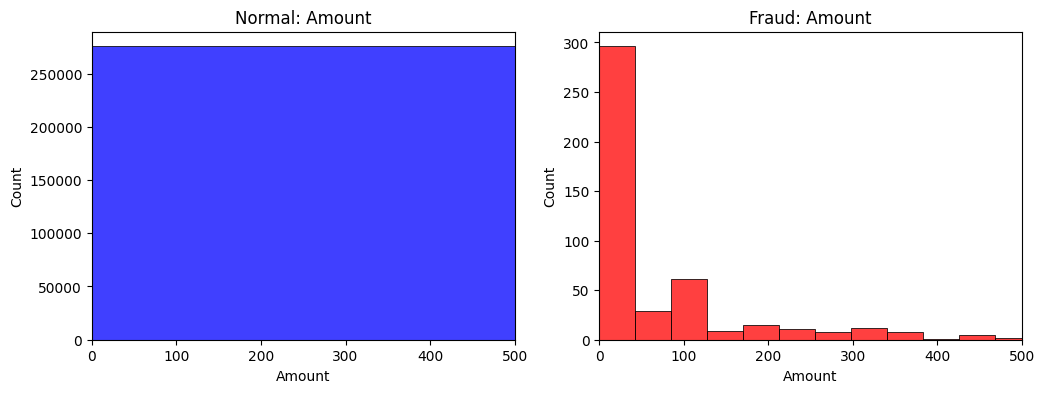

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[df["Class"] == 0]["Amount"], bins=50, ax=ax[0], color="blue")
ax[0].set_title("Normal: Amount")
ax[0].set_xlim(0, 500)
sns.histplot(df[df["Class"] == 1]["Amount"], bins=50, ax=ax[1], color="red")
ax[1].set_title("Fraud: Amount")
ax[1].set_xlim(0, 500)
plt.show()

In [5]:
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split

df["scaled_amount"] = RobustScaler().fit_transform(df[["Amount"]])
df["scaled_time"] = RobustScaler().fit_transform(df[["Time"]])
df = df.drop(["Amount", "Time"], axis=1)

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Fraud in train:", y_train.sum(), "| Fraud in test:", y_test.sum())

(227845, 30) (56962, 30)
Fraud in train: 394 | Fraud in test: 98


In [6]:
df = pd.read_csv("creditcard.csv")
print(df.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [7]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score,
                             precision_recall_curve)

results = {}

def evaluate(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, digits=4))
    print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
    pr_auc = average_precision_score(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)
    print(f"PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc:.4f}")
    results[name] = {"PR-AUC": pr_auc, "ROC-AUC": roc_auc}

In [8]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
evaluate("Logistic Regression (baseline)", lr, X_test, y_test)

===== Logistic Regression (baseline) =====
              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     56864
           1     0.8182    0.6429    0.7200        98

    accuracy                         0.9991     56962
   macro avg     0.9088    0.8213    0.8598     56962
weighted avg     0.9991    0.9991    0.9991     56962

Confusion matrix:
 [[56850    14]
 [   35    63]]
PR-AUC: 0.7402 | ROC-AUC: 0.9582


In [9]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("Before:", y_train.value_counts().to_dict())
print("After: ", y_train_sm.value_counts().to_dict())

lr_sm = LogisticRegression(max_iter=1000)
lr_sm.fit(X_train_sm, y_train_sm)
evaluate("Logistic Regression + SMOTE", lr_sm, X_test, y_test)

Before: {0: 227451, 1: 394}
After:  {0: 227451, 1: 227451}
===== Logistic Regression + SMOTE =====
              precision    recall  f1-score   support

           0     0.9999    0.9748    0.9872     56864
           1     0.0591    0.9184    0.1110        98

    accuracy                         0.9747     56962
   macro avg     0.5295    0.9466    0.5491     56962
weighted avg     0.9982    0.9747    0.9857     56962

Confusion matrix:
 [[55430  1434]
 [    8    90]]
PR-AUC: 0.7235 | ROC-AUC: 0.9712


In [10]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf, X_test, y_test)

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
evaluate("XGBoost", xgb, X_test, y_test)

===== Random Forest =====
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962

Confusion matrix:
 [[56859     5]
 [   18    80]]
PR-AUC: 0.8608 | ROC-AUC: 0.9528
===== XGBoost =====
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.8737    0.8469    0.8601        98

    accuracy                         0.9995     56962
   macro avg     0.9367    0.9234    0.9299     56962
weighted avg     0.9995    0.9995    0.9995     56962

Confusion matrix:
 [[56852    12]
 [   15    83]]
PR-AUC: 0.8764 | ROC-AUC: 0.9760


In [11]:
pd.DataFrame(results).T.sort_values("PR-AUC", ascending=False)

,PR-AUC,ROC-AUC
XGBoost,0.876389,0.975954
Random Forest,0.860751,0.952793
Logistic Regression (baseline),0.740246,0.958185
Logistic Regression + SMOTE,0.723502,0.971219


In [12]:
  df = pd.read_csv("creditcard.csv")
  df["scaled_amount"] = RobustScaler().fit_transform(df[["Amount"]])
  df["scaled_time"] = RobustScaler().fit_transform(df[["Time"]])
  df = df.drop(["Amount", "Time"], axis=1)

In [13]:
import joblib
joblib.dump(xgb, "xgb_model.pkl")

['xgb_model.pkl']

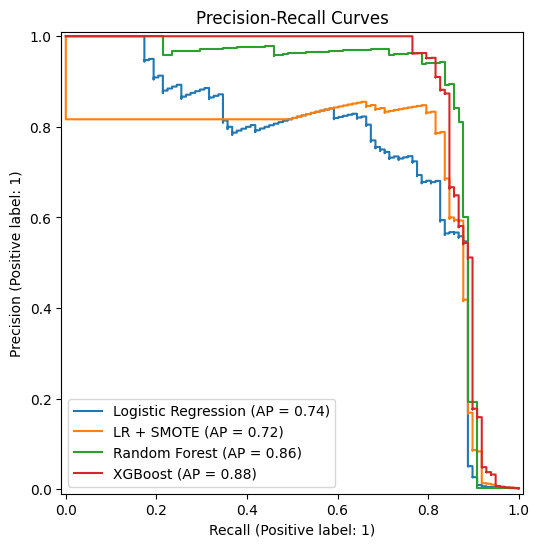

In [14]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(8, 6))
models = {"Logistic Regression": lr, "LR + SMOTE": lr_sm,
          "Random Forest": rf, "XGBoost": xgb}
for name, m in models.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
plt.title("Precision-Recall Curves")
plt.show()

In [18]:
import joblib
xgb = joblib.load("xgb_model.pkl")

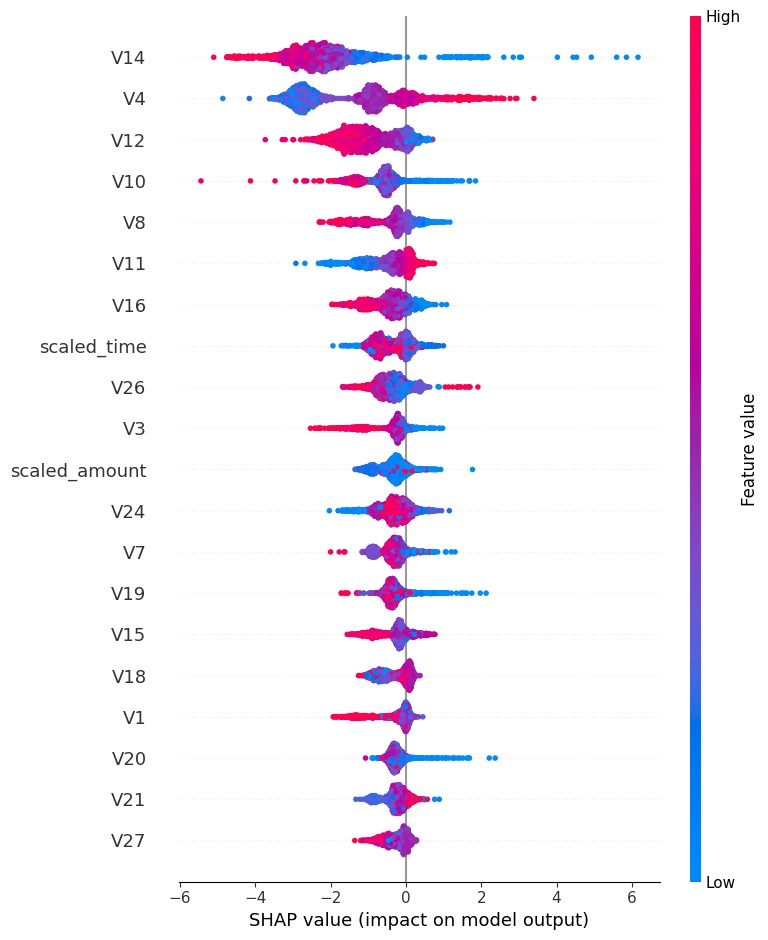

In [19]:
import shap
import xgboost as xgb_lib

sample = X_test.sample(2000, random_state=42)
contribs = xgb.get_booster().predict(xgb_lib.DMatrix(sample), pred_contribs=True)
shap_values = contribs[:, :-1]   # last column is the bias term
shap.summary_plot(shap_values, sample)

In [20]:
y_prob = xgb.predict_proba(X_test)[:, 1]

for t in [0.3, 0.5, 0.7, 0.9]:
    y_pred = (y_prob >= t).astype(int)
    tp = ((y_pred == 1) & (y_test == 1)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn)
    print(f"threshold {t}: precision={precision:.3f}, recall={recall:.3f}, "
          f"frauds caught={tp}/{tp + fn}, false alarms={fp}")

threshold 0.3: precision=0.856, recall=0.847, frauds caught=83/98, false alarms=14
threshold 0.5: precision=0.874, recall=0.847, frauds caught=83/98, false alarms=12
threshold 0.7: precision=0.882, recall=0.837, frauds caught=82/98, false alarms=11
threshold 0.9: precision=0.910, recall=0.827, frauds caught=81/98, false alarms=8


In [21]:
import joblib
joblib.dump(xgb, "xgb_model.pkl")

demo = X_test.copy()
demo["Class"] = y_test
demo = pd.concat([
    demo[demo["Class"] == 1].sample(20, random_state=42),
    demo[demo["Class"] == 0].sample(180, random_state=42),
]).sample(frac=1, random_state=42)
demo.to_csv("demo_transactions.csv", index=False)
print(demo.shape)

(200, 31)


In [22]:
demo = pd.read_csv("demo_transactions.csv")
print(demo[demo["Class"] == 1].index.tolist())

[1, 21, 30, 31, 47, 52, 63, 80, 94, 97, 100, 106, 111, 136, 146, 153, 154, 158, 180, 196]
